In [1]:
import sys
sys.path.insert(1,'/Users/dengyuyao/Github/SCAM/raw')
from raw_prepro import *
import glob
import tifffile as tiff

In [2]:
all_raws=glob.glob('./*.raw')

In [3]:
for raw in all_raws:
    raw2d = cut_raw_black_lines(raw)
    B2d = extract_B_raw(raw2d)
    if 'cam1' in raw or 'uv' in raw:
        tiff.imwrite(raw.replace('.raw','_B.tiff')
                     ,B2d,compression=None)
    if 'cam0' in raw or 'g' in raw:
    
        G2d=extract_G_raw(raw2d)
        tiff.imwrite(raw.replace('.raw','_G.tiff'),G2d,compression=None)
    
    # R2d=extract_R_raw(raw2d)
    # tiff.imwrite(raw.replace('.raw','_R.tiff'),R2d,compression=None)

In [10]:
B2d-4096

array([[   16,    16,    16, ..., 65504,    16,    16],
       [   16,    16,    16, ..., 65504,    16,    16],
       [   48,    48, 65520, ...,    16,    32,    32],
       ...,
       [65520, 65520,    32, ...,     0,    64,    64],
       [   48,    48, 65504, ...,    48, 65488, 65488],
       [   48,    48, 65504, ...,    48, 65488, 65488]], dtype=uint16)

In [11]:
denoise=B2d-4096

In [23]:
np.mean(denoise)

21325.261818748055

In [13]:
import matplotlib.pyplot as plt

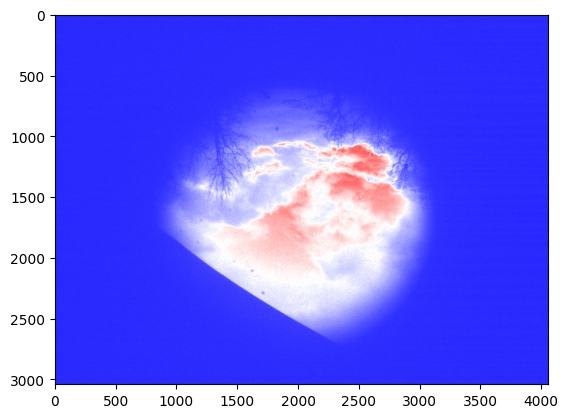

In [37]:
plt.imshow(B2d/np.max(B2d),cmap='bwr')

In [22]:
np.mean(B2d)#,np.mean(G2d)

4123.89511574795

In [7]:
# for raw in all_raws:
#     raw2d = cut_raw_black_lines(raw)
#     G1_2d=extract_G1_raw(raw2d)
#     tiff.imwrite(raw.replace('.raw','_G1.tiff'),G1_2d,compression=None)
#     G2_2d=extract_G2_raw(raw2d)
#     tiff.imwrite(raw.replace('.raw','_G2.tiff'),G2_2d,compression=None)

In [8]:
G1 = raw2d[0::2, 1::2]
G2 = raw2d[1::2, 0::2]

In [19]:
np.mean(G1),np.mean(G2)

(6168.3606301256095, 6167.794892556836)

In [10]:
import matplotlib.pyplot as plt

In [20]:
Gmean[1250,850],G1[1250,850],G2[1250,850]

(9856.0, 41888, 43360)

In [21]:
G1[1250,850]+G2[1250,850]

/var/folders/l4/pwnj9skj16x_35bhhr9305900000gn/T/ipykernel_1254/1097253677.py:1: RuntimeWarning: overflow encountered in scalar add
  G1[1250,850]+G2[1250,850]


19712

In [22]:
19712/2

9856.0

In [ ]:
G = ((G1.astype(np.uint16) + G2.astype(np.uint16)) // 2).astype(sensor_raw.dtype)

In [29]:
Gmean=((G1.astype(np.uint32)+G2.astype(np.uint32))//2).astype(Gmean.dtype)

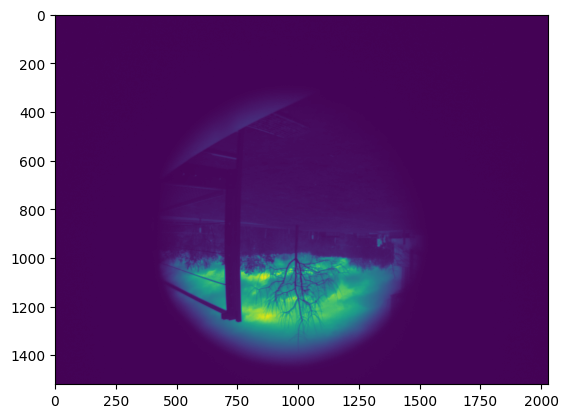

In [30]:
plt.imshow(Gmean)

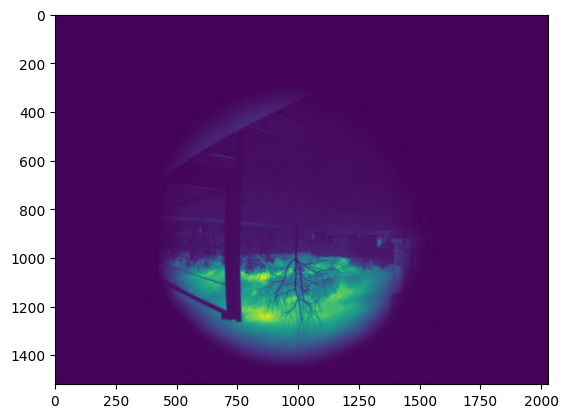

In [15]:
plt.imshow(G2)

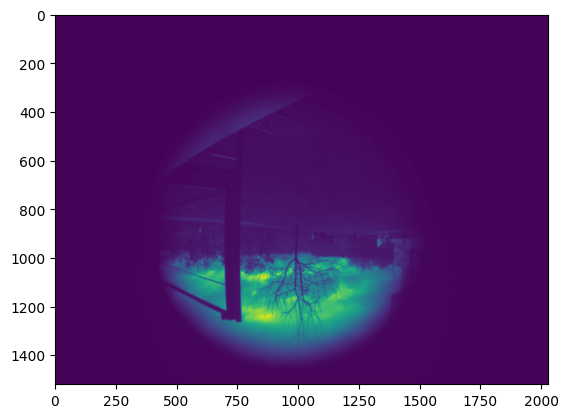

In [14]:
plt.imshow(G1)

In [13]:
G1==G2

array([[False, False, False, ...,  True, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False,  True],
       ...,
       [False, False,  True, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False,  True, False, ..., False, False, False]])

(array([2.762229e+06, 7.375200e+04, 4.762400e+04, 4.365600e+04,
        5.152300e+04, 4.520800e+04, 3.628500e+04, 1.700000e+04,
        4.541000e+03, 7.420000e+02]),
 array([ 3712. ,  7980.8, 12249.6, 16518.4, 20787.2, 25056. , 29324.8,
        33593.6, 37862.4, 42131.2, 46400. ]),
 <BarContainer object of 10 artists>)

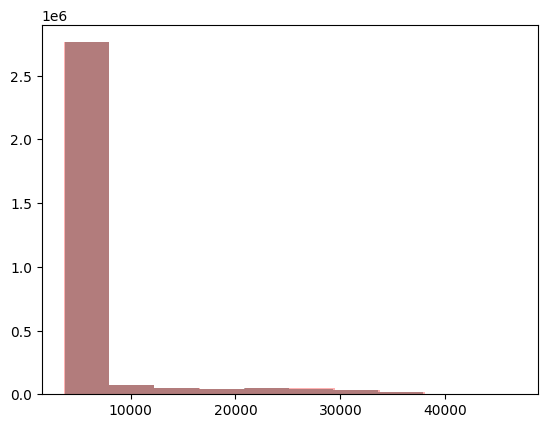

In [24]:
plt.hist(G1.flatten(),color='red',alpha=.3)
plt.hist(G2.flatten(),color='k',alpha=.3)


In [12]:
raw

'./matlab_g4.raw'

In [13]:
np.mean(G2d),np.mean(B2d)

(5861.738801515623, 5310.055257967404)

In [9]:
uv_raw_eg = cut_raw_black_lines('./matlab_uv4.raw')
uv_B=extract_B_raw(uv_raw_eg)
uv_G=extract_G_raw(uv_raw_eg)
#uv_G1=extract_G1_raw(uv_raw_eg)
#uv_G2=extract_G2_raw(uv_raw_eg)
uv_R=extract_R_raw(uv_raw_eg)

In [14]:
np.mean(uv_G),np.mean(uv_B),np.mean(uv_R),np.mean(G2d),np.mean(B2d),np.mean(R2d)

(8495.459916433094,
 8673.489847399564,
 8522.883598048375,
 6168.077761341223,
 5310.055257967404,
 4228.09384407765)

(array([10543008.,   616996.,   167064.,   135244.,   113072.,   113188.,
          124360.,   139540.,   119788.,   257980.]),
 array([ 1808. ,  8179.2, 14550.4, 20921.6, 27292.8, 33664. , 40035.2,
        46406.4, 52777.6, 59148.8, 65520. ]),
 <BarContainer object of 10 artists>)

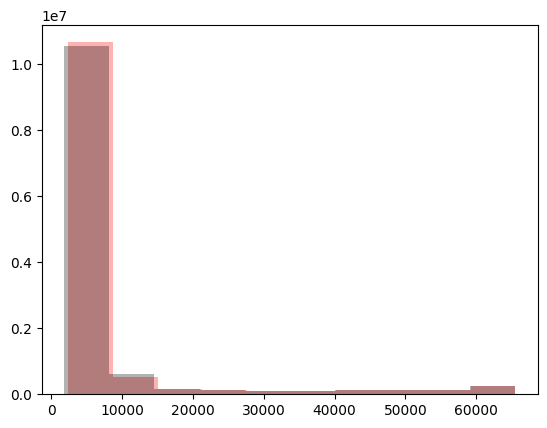

In [27]:
plt.hist(uv_G1.flatten(),color='red',alpha=.3)
plt.hist(uv_G2.flatten(),color='k',alpha=.3)
